# Modelos alternativos
## Proyecto Integrador — Avance 4

**Equipo 1**

| Nombre | Matrícula |
|---|---|
| Isaura Yutsil Flores Escamilla | A01796552 |
| Paola Alejandra León Guarneros | A01796230 |
| Dylan Ulises Quiroz Hernández  | A01796578 |

**Fecha:** 25 de octubre de 2026

## Resumen

En este avance se construyen y comparan **seis modelos alternativos** para reconocer las siete actividades de manejo manual de cargas (`N`, `LF`, `K`, `PT`, `LT`, `W`, `PF`). La entrada es **sólo la captura de movimiento (MVNX)**: 30 variables de postura, alcance de las manos, velocidad y apoyo de los pies, a 12 Hz y en ventanas de 4 s. Los avances anteriores mostraron que el movimiento es la fuente que mejor separa las actividades.

Los modelos cubren familias distintas: árboles de decisión sobre características manuales, una red convolucional y cuatro redes recurrentes (GRU, LSTM, sLSTM y mLSTM). En las redes recurrentes se compara además el entrenamiento desde cero con el preentrenamiento autosupervisado CPC.

Todos se evalúan **dejando un sujeto fuera (LOSO)** con los sujetos 1–12 y se comparan emparejados por sujeto. Los sujetos 13 y 14 quedan reservados para la prueba final. Con esa comparación se eligen los **dos mejores modelos**, se ajustan sus hiperparámetros y se selecciona el **modelo final**.

## Modelos que se comparan

| # | Modelo | Familia | Entrada | Qué aporta a la comparación |
|---|---|---|---|---|
| 1 | **Random Forest / HistGradientBoosting** | Árboles de decisión | Características manuales por ventana: media, desviación, mínimo, máximo y pendiente de cada variable | Referencia clásica sin aprendizaje profundo. Indica cuánto se logra resumiendo la ventana, sin modelar su dinámica |
| 2 | **CNN 1D causal** | Convolucional | Serie de 48 pasos × 30 variables | El mismo encoder de las redes recurrentes, sin recurrencia. Indica si la recurrencia aporta sobre la convolución |
| 3 | **GRU** | Recurrente clásica | Serie de 48 pasos × 30 variables | Red recurrente del artículo de CPC para actividades (Haresamudram et al., 2020) |
| 4 | **LSTM** | Recurrente clásica | Serie de 48 pasos × 30 variables | Agrega una compuerta de salida y un estado de celda separado. Contrasta con la GRU, que es más simple |
| 5 | **sLSTM** | xLSTM, recurrente con memoria escalar | Serie de 48 pasos × 30 variables | Compuerta de entrada exponencial, normalizador y mezcla de memoria por *heads* (Beck et al., 2024) |
| 6 | **mLSTM** | xLSTM, paralela con memoria matricial | Serie de 48 pasos × 30 variables | Memoria clave → valor que procesa la ventana en paralelo, cercana a la atención lineal (Beck et al., 2024) |

**Variantes de entrenamiento.** En las redes 3–6 se compara el **entrenamiento desde cero** con el **ajuste fino tras el preentrenamiento CPC**. Se conserva la variante con mejor desempeño de cada red. La sonda lineal sobre CPC congelado y sobre la red sin entrenar se usan sólo como controles para saber qué aprende CPC por sí solo.

**Referencia mínima.** La regresión logística sobre la media de cada variable (F1 macro 0.615) aparece en las tablas como piso de desempeño, pero no se cuenta entre los seis modelos.

**Mismas condiciones para todos:** las mismas ventanas, la misma etiqueta (`label_mvnx` del instante final), las mismas 12 rondas LOSO con el mismo sujeto de validación interna y la misma métrica (F1 macro).

# 1. Configuración

In [1]:
import json, re
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from sklearn.metrics import confusion_matrix, f1_score

SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final del modelo elegido
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas LOSO ya entrenadas (GRU, LSTM, sLSTM)
RUN_DIR = REPO_DIR / "checkpoints" / f"avance4_fs{TARGET_FS}"                     # rondas de los modelos nuevos
RUN_DIR.mkdir(parents=True, exist_ok=True)
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
LABEL_NAMES = {"N": "Postura neutral", "LF": "Levantar desde el piso", "K": "Mantener levantado", "PT": "Colocar en la mesa",
               "LT": "Levantar desde la mesa", "W": "Caminar / cargar", "PF": "Colocar en el piso"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | {TARGET_FS} Hz | ventana de {WIN} pasos ({WIN / TARGET_FS:.0f} s)")

PyTorch 2.11.0 | dispositivo: mps | 12 Hz | ventana de 48 pasos (4 s)


# 2. Datos de entrada

**Fuente.** La exportación sincronizada de la captura de movimiento a 12 Hz. Por cada ensayo contiene las 782 columnas MVNX remuestreadas y la etiqueta `label_mvnx`, anotada sobre el propio MVNX. La sEMG no se usa.

**Variables.** De las 782 columnas se calculan **30 variables** con significado físico, en cuatro grupos:

- **Postura:** ángulos articulares de tronco, cuello, hombros, codos, muñecas, caderas y rodillas.
- **Alturas y alcance:** altura de la pelvis, de la cabeza y de las manos, y distancia horizontal de cada mano a la pelvis.
- **Velocidades:** de la pelvis, de las manos y del tronco.
- **Apoyo:** contacto del talón y de la punta de cada pie (0/1).

Los lados son fijos (`izq_*`, `der_*`).

**Ensayos.** Cada archivo MVNX es un ensayo. A los de la exportación se suman 3 ensayos bimanuales del sujeto 7 que se habían excluido sólo por fallas en la sEMG. Se leen del MVNX crudo con el mismo remuestreo: pasa-bajas Butterworth de orden 4 a 4.8 Hz, con fase cero, e interpolación lineal.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}
SIDES = (("izq", "Left"), ("der", "Right"))


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"


def feature_group(name):
    return {"°": "Postura", "m": "Alturas y alcance", "m/s": "Velocidades", "rad/s": "Velocidades", "0/1": "Apoyo"}[feature_unit(name)]

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")
variables = (pd.DataFrame({"variable": CHANNELS, "unidad": [feature_unit(n) for n in CHANNELS], "grupo": [feature_group(n) for n in CHANNELS]})
             .groupby("grupo", sort=False).agg(n=("variable", "size"), unidades=("unidad", lambda u: ", ".join(dict.fromkeys(u))),
                                               variables=("variable", ", ".join)))
display(variables.style.set_properties(subset="variables", **{"text-align": "left", "white-space": "normal"}))

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


,n,unidades,variables
grupo,,,
Postura,14,°,"tronco_flexion, cuello_flexion, izq_hombro_flexion, izq_hombro_abduccion, izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_hombro_flexion, der_hombro_abduccion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion"
Alturas y alcance,6,m,"pelvis_altura, cabeza_altura, izq_mano_altura, izq_mano_alcance, der_mano_altura, der_mano_alcance"
Velocidades,6,"m/s, rad/s","pelvis_vel_horizontal, pelvis_vel_vertical, izq_mano_rapidez, der_mano_rapidez, pelvis_giro, tronco_vel_angular"
Apoyo,4,0/1,"izq_talon, izq_punta, der_talon, der_punta"


## 2.1 Ventanas y etiqueta

- **Ventana:** 48 pasos (4 s) de las 30 variables. Una ventana nunca cruza dos ensayos.
- **Etiqueta:** la actividad del **instante final** de la ventana. La tarea es "qué actividad ocurre en *t* dados los 4 s previos". Se descartan las ventanas cuyo instante final no tiene etiqueta.
- **Frecuencia:** una ventana etiquetada cada 0.5 s. El preentrenamiento CPC usa además ventanas sin etiqueta, una cada 2 s.

In [5]:
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

counts = pd.crosstab(sup_cv["target"].map(dict(enumerate(LABELS))), sup_cv["subject"]).reindex(LABELS)
counts.columns = [f"s{s}" for s in counts.columns]
counts.loc["total"] = counts.sum()
counts["total"] = counts.sum(axis=1)
counts["% ventanas"] = (100 * counts["total"] / counts.loc["total", "total"]).round(1)
counts.index.name, counts.columns.name = "actividad", "sujeto"
print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")
display(counts)

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498


sujeto,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,total,% ventanas
actividad,,,,,,,,,,,,,,
N,1845,1228,1439,1376,1278,1383,1666,1408,1766,1279,2037,1286,17991,43.9
LF,304,222,268,316,384,270,332,345,267,240,391,250,3589,8.8
K,524,156,244,201,243,216,253,239,199,201,711,238,3425,8.4
PT,531,405,508,501,539,475,566,621,458,586,594,493,6277,15.3
LT,337,346,337,314,371,314,381,346,310,281,332,309,3978,9.7
W,133,241,264,253,298,279,225,316,214,245,180,312,2960,7.2
PF,248,170,237,181,245,194,267,272,205,227,279,199,2724,6.7
total,3922,2768,3297,3142,3358,3131,3690,3547,3419,3059,4524,3087,40944,100.0


## 2.2 Formato de entrada a cada modelo

| Modelos | Qué recibe | Forma | Preparación |
|---|---|---|---|
| Random Forest / HistGradientBoosting | 5 estadísticas de cada variable en la ventana: media, desviación, mínimo, máximo y pendiente (por segundo) | `(ventanas, 150)` | En unidades físicas; los árboles no necesitan escalado |
| CNN, GRU, LSTM, sLSTM, mLSTM | La ventana completa | `(ventanas, 30 variables, 48 pasos)` | Escalado robusto por variable, ajustado **en cada ronda** sólo con los sujetos de entrenamiento: recorte en los cuantiles 0.1 % y 99.9 % y `(x − mediana) / (q95 − q5)`. Los contactos (0/1) no se modifican |

In [6]:
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2


def window_stats(starts, chunk=8_192):
    """Las 5 estadísticas de cada variable en cada ventana -> (ventanas, 150), en unidades físicas."""
    view = sliding_window_view(signals_raw, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


def fit_scaler(train_subjects, seed=SEED):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


TABULAR_COLUMNS = [f"{s}_{n}" for s in STATS for n in CHANNELS]
X_tab = pd.DataFrame(window_stats(starts_of(sup_cv)), index=sup_cv.index, columns=TABULAR_COLUMNS)
print(f"Árboles  -> X_tab: {X_tab.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH} variables)")
display(X_tab.loc[:, [f"{s}_der_codo_flexion" for s in STATS]].head(3).round(2))

# Ejemplo de lo que recibe una red: ventanas escaladas con los sujetos de entrenamiento de la primera ronda (2–11)
scaled = apply_scaler(fit_scaler(tuple(s for s in CV_SUBJECTS if s not in (1, 2))))
example = sliding_window_view(scaled, WIN, axis=0)[starts_of(sup_cv.head(256))]
print(f"Redes    -> x: {example.shape}  (ventanas, variables, pasos) | etiqueta y: {sup_cv['target'].head(256).to_numpy().shape}")

Árboles  -> X_tab: (40944, 150)  (ventanas, 5 estadísticas × 30 variables)


,media_der_codo_flexion,desv_der_codo_flexion,min_der_codo_flexion,max_der_codo_flexion,pendiente_der_codo_flexion
0,3.30,0.02,3.27,3.34,-0.0
1,3.30,0.02,3.27,3.33,0.0
2,3.29,0.01,3.25,3.32,0.0


Redes    -> x: (256, 30, 48)  (ventanas, variables, pasos) | etiqueta y: (256,)


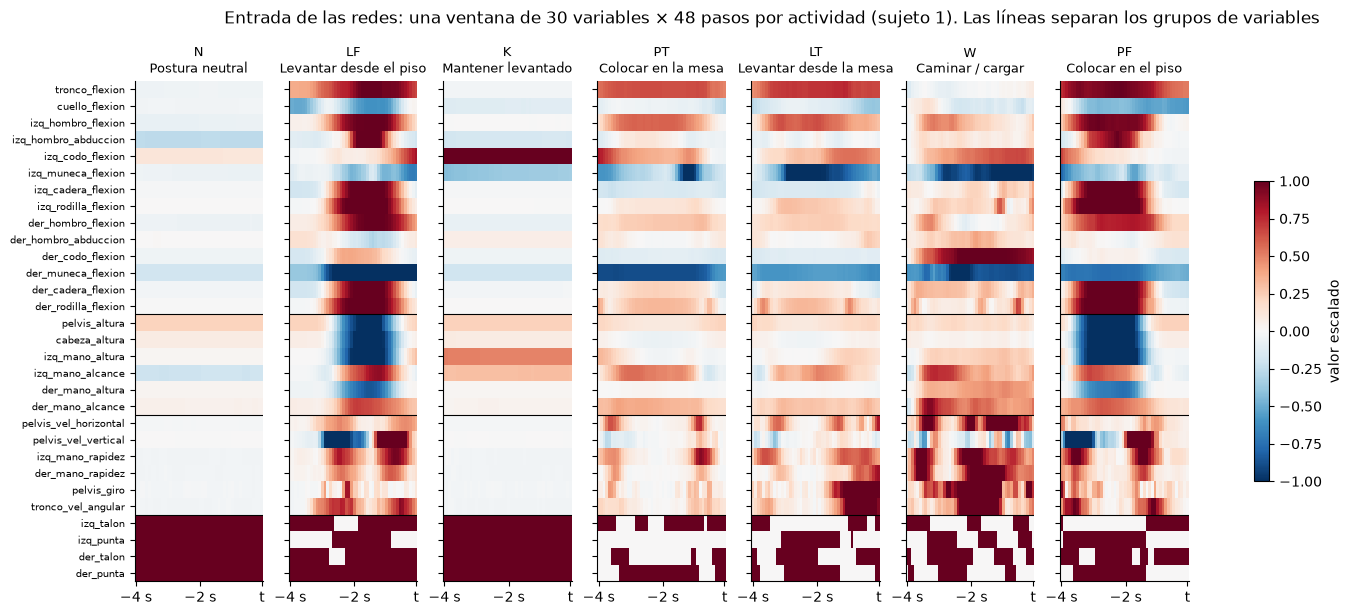

In [7]:
# Una ventana representativa de cada actividad (sujeto 1): la de mayor proporción de pasos con esa actividad
subj = sup_cv[sup_cv["subject"] == 1]
starts = starts_of(subj)
purity = (sliding_window_view(labels_series, WIN)[starts] == subj["target"].to_numpy()[:, None]).mean(axis=1)
fig, axes = plt.subplots(1, len(LABELS), figsize=(17, 6.5), sharey=True)
for k, (ax, lab) in enumerate(zip(axes, LABELS)):
    i = np.flatnonzero(subj["target"].to_numpy() == k)[np.argmax(purity[subj["target"].to_numpy() == k])]
    im = ax.imshow(scaled[starts[i]:starts[i] + WIN].T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
    for g in np.flatnonzero([feature_group(a) != feature_group(b) for a, b in zip(CHANNELS, CHANNELS[1:])]):
        ax.axhline(g + 0.5, color="k", lw=0.8)
    ax.set(xticks=[0, 24, 47], xticklabels=["−4 s", "−2 s", "t"])
    ax.set_title(f"{lab}\n{LABEL_NAMES[lab]}", fontsize=9)
axes[0].set(yticks=range(N_CH), yticklabels=CHANNELS)
axes[0].tick_params(axis="y", labelsize=7)
fig.colorbar(im, ax=axes, shrink=0.6, label="valor escalado")
fig.suptitle("Entrada de las redes: una ventana de 30 variables × 48 pasos por actividad (sujeto 1). Las líneas separan los grupos de variables", y=0.99)
plt.show()

# 3. Cómo se evalúan los modelos

- **Validación cruzada dejando un sujeto fuera (LOSO), 12 rondas.** En cada ronda se evalúa a un sujeto que el modelo nunca vio, como si fuera una persona nueva. El sujeto siguiente de la lista es la **validación interna**: decide la parada temprana y la elección de época. Los 10 restantes entrenan. Ni el escalador ni el entrenamiento ven datos del sujeto evaluado.
- **Métrica: F1 macro.** Promedia el F1 de las siete actividades con el mismo peso. La exactitud la dominaría `N`, que es la clase más frecuente.

Cada modelo reporta:

| Métrica | Qué indica |
|---|---|
| **F1 macro, media ± desviación** entre los 12 sujetos | Desempeño esperado en una persona nueva y cuánto varía de una persona a otra |
| **F1 del peor sujeto** | Qué tan mal puede ir con una persona nueva |
| **F1 por actividad** (predicciones de los 12 sujetos juntas) | Qué actividades reconoce bien y cuáles no |
| **Matriz de confusión** normalizada por actividad real | Con qué actividad se confunde cada una. La diagonal es la proporción de aciertos de cada actividad (*recall*) |

In [8]:
RESULTS = {}   # resumen de cada modelo, para la sección de comparativos


def inner_validation_subject(held_out):
    """El siguiente sujeto de la lista (circular) decide la parada temprana."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def check_windows(r, s, where):
    held = sup_cv[sup_cv["subject"] == s]
    assert r["index"] == held.index.tolist() and r["y"] == held["target"].tolist(), f"{where}, sujeto {s}: otras ventanas"


def load_saved_rounds(folder, method, stages=None, name="ronda_s{:02d}_semilla0.json"):
    """Rondas LOSO ya entrenadas: etiquetas y predicciones del sujeto evaluado, y minutos de entrenamiento
    (la suma de las etapas `stages`, o el total de la ronda)."""
    rounds = {}
    for s in CV_SUBJECTS:
        r = json.loads((SAVED_DIR / folder / name.format(s)).read_text())
        check_windows(r, s, folder)
        minutes = sum(r["info"][k]["minutes"] for k in stages) if stages else r["minutes"]
        rounds[s] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"][method]), "minutes": minutes}
    return rounds


def subject_f1(rounds):
    return pd.Series({s: f1_score(r["y"], r["pred"], average="macro") for s, r in sorted(rounds.items())})


def report(model, rounds, variant=None):
    """Métricas finales de un modelo y su matriz de confusión; guarda el resumen en RESULTS."""
    f1_subject = subject_f1(rounds)
    y = np.concatenate([r["y"] for _, r in sorted(rounds.items())])
    pred = np.concatenate([r["pred"] for _, r in sorted(rounds.items())])
    f1_class = f1_score(y, pred, labels=range(len(LABELS)), average=None, zero_division=0)
    RESULTS[model] = {"variante": variant or "—", "f1_sujeto": f1_subject, "f1_clase": pd.Series(f1_class, index=LABELS),
                      "minutos_por_ronda": np.mean([r["minutes"] for r in rounds.values()])}

    name = model if variant is None else f"{model} ({variant})"
    table = pd.DataFrame({("F1 macro", "media ± desv."): [f"{f1_subject.mean():.3f} ± {f1_subject.std():.3f}"],
                          ("F1 macro", "peor sujeto"): [f"{f1_subject.min():.3f} (sujeto {f1_subject.idxmin()})"],
                          **{("F1 por actividad", lab): [round(v, 3)] for lab, v in zip(LABELS, f1_class)}}, index=[name])
    display(table)

    cm = confusion_matrix(y, pred, labels=range(len(LABELS)), normalize="true")
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 else "black")
    ax.set(xticks=range(len(LABELS)), xticklabels=LABELS, yticks=range(len(LABELS)), yticklabels=LABELS,
           xlabel="actividad predicha", ylabel="actividad real", title=f"{name}: matriz de confusión (12 sujetos)")
    plt.show()


def report_best_variant(model, variants):
    """Reporta la variante de entrenamiento con mayor F1 macro medio y resume la otra en una línea."""
    means = {v: subject_f1(rounds).mean() for v, rounds in variants.items()}
    best = max(means, key=means.get)
    for v in variants:
        if v != best:
            print(f"Variante {v}: F1 macro {means[v]:.3f} ± {subject_f1(variants[v]).std():.3f}. "
                  f"Se reporta la variante {best} ({means[best]:.3f}).")
    report(model, variants[best], variant=best)

## 3.1 Entrenamiento común de las redes

Las cinco redes comparten la entrada, el encoder, la cabeza de clasificación y el procedimiento de entrenamiento. Sólo cambia la **red de contexto** que va después del encoder, que es lo que define cada modelo.

```
ventana x (30 × 48) → encoder convolucional causal → z (48 × 128) → red de contexto → c (48 × 256) → cabeza → 7 actividades
```

- **Encoder:** 3 convoluciones 1D causales (32, 64 y 128 filtros, núcleo 3, ReLU y dropout 0.2). Cada instante sólo ve el pasado.
- **Cabeza:** LayerNorm, dropout 0.2 y una capa lineal, aplicadas al estado de contexto del **último instante** de la ventana. La CNN, que no tiene red de contexto, usa la media y el máximo de `z` en la ventana.
- **Ajuste fino con LP-FT:** primero se entrena sólo la cabeza con la red congelada (hasta 20 épocas). Después se entrena toda la red, con tasa de aprendizaje de 1e-3 para la cabeza y 1e-4 para el resto (hasta 30 épocas). Se usa entropía cruzada ponderada por clase y se conserva la época con mejor F1 macro en el sujeto de validación interna (paciencia 5).
- **Preentrenamiento CPC (variante opcional):** antes del ajuste fino, el encoder y la red de contexto aprenden sin etiquetas. Desde el contexto `c_t` predicen la representación de los siguientes 12 pasos (1 s) y la distinguen de las de otras ventanas del mismo sujeto (pérdida InfoNCE). Se conserva la época cuya representación congelada da el mejor F1 en la validación interna, medido con un clasificador lineal.

In [9]:
import copy, math, time
from datetime import datetime

import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Z_DIM, C_DIM, FEAT_DIM = 128, 256, 256
FT = {"lp_epochs": 20, "lp_patience": 3, "lp_lr": 1e-3, "epochs": 30, "patience": 5, "lr_head": 1e-3, "lr_backbone": 1e-4, "batch": 256,
      "wd": 1e-4, "head_dropout": 0.2}
CPC_CFG = {"epochs": 20, "eval_every": 2, "patience": 3, "batch": 128, "lr": 5e-4, "horizons": tuple(range(1, 13)), "n_anchors": 4}
GRAD_CLIP, PROBE_TRAIN_MAX = 1.0, 15_000
LOG_FILE = RUN_DIR / "progreso.log"
AR_BUILDERS = {}   # red de contexto de cada modelo; la registra su sección


def log(message):
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


# ----------------------------- Datos en el dispositivo -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (B, 30, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_split(train_subjects, val_subjects, held_subjects=()):
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    return {"train_subjects": tuple(train_subjects), "probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train),
            "val": eval_set(sup_cv[sup_cv["subject"].isin(val_subjects)]), "held": eval_set(sup_cv[sup_cv["subject"].isin(held_subjects)]),
            "n_steps": max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_CFG["batch"])}


def make_sets(held_out):
    inner_val, train_subjects = split_subjects(held_out)
    return make_split(train_subjects, (inner_val,), (held_out,))


# ----------------------------- Modelo -----------------------------
class CausalEncoder(nn.Module):
    """x: (B, 30, T) -> z: (B, 128, T). Relleno sólo a la izquierda: z_t depende de x_{t-6..t}, nunca del futuro."""

    def __init__(self, channels=(32, 64, 128), k=3, dropout=0.2):
        super().__init__()
        self.left_pad = k - 1
        self.convs = nn.ModuleList([nn.Conv1d(a, b, k) for a, b in zip((N_CH,) + channels[:-1], channels)])
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        for conv in self.convs:
            x = self.dropout(F.relu(conv(F.pad(x, (self.left_pad, 0)))))
        return x


class Backbone(nn.Module):
    """Encoder + red de contexto del modelo (ninguna en la CNN)."""

    def __init__(self, kind):
        super().__init__()
        self.encoder = CausalEncoder()
        self.ar = None if kind == "CNN" else AR_BUILDERS[kind]()

    def forward(self, x):
        z = self.encoder(x).transpose(1, 2)                      # (B, T, 128)
        return z, (None if self.ar is None else self.ar(z))      # c: (B, T, 256)

    def features(self, x):
        z, c = self(x)
        return torch.cat([z.mean(1), z.amax(1)], dim=1) if c is None else c[:, -1]


def build_backbone(kind, seed):
    torch.manual_seed(seed)
    return Backbone(kind).to(DEVICE)


class Classifier(nn.Module):
    def __init__(self, backbone, dropout=0.2):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(nn.LayerNorm(FEAT_DIM), nn.Dropout(dropout), nn.Linear(FEAT_DIM, len(LABELS)))

    def forward(self, x):
        return self.head(self.backbone.features(x))


class CPC(nn.Module):
    """Desde c_t predice z_{t+k} (k = 1..12) con una matriz W_k por horizonte; InfoNCE con las otras ventanas del batch como negativos."""

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.heads = nn.ModuleList([nn.Linear(C_DIM, Z_DIM, bias=False) for _ in CPC_CFG["horizons"]])

    def forward(self, x):
        z, c = self.backbone(x)
        anchors = torch.randint(max(1, WIN // 8), WIN - max(CPC_CFG["horizons"]), (CPC_CFG["n_anchors"],)).tolist()
        target = torch.arange(len(x), device=x.device)
        return torch.stack([F.cross_entropy(head(c[:, t]) @ z[:, t + k].T, target)
                            for t in anchors for k, head in zip(CPC_CFG["horizons"], self.heads)]).mean()


# ----------------------------- Entrenamiento -----------------------------
@torch.no_grad()
def extract(backbone, starts, batch=512):
    backbone.eval()
    return torch.cat([backbone.features(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts, batch=512):
    model.eval()
    return np.concatenate([model(get_windows(starts[s:s + batch])).argmax(1).cpu().numpy() for s in range(0, len(starts), batch)])


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


class SameSubjectSampler:
    """Batches de CPC: inicios de ventana al azar, todos del mismo sujeto (los negativos son de la misma persona)."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_CFG["batch"], replace=len(pool) < CPC_CFG["batch"])


def probe_f1(backbone, sets):
    """F1 en la validación interna de un clasificador lineal sobre la representación congelada."""
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    clf.fit(extract(backbone, sets["probe_train"]["starts"]).cpu().numpy(), sets["probe_train"]["y"])
    return f1_score(sets["val"]["y"], clf.predict(extract(backbone, sets["val"]["starts"]).cpu().numpy()), average="macro")


def train_cpc(kind, sets, seed):
    t0 = time.time()
    model = CPC(build_backbone(kind, seed)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_CFG["lr"])
    sampler = SameSubjectSampler(sets["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.backbone.state_dict())}, 0
    for epoch in range(1, CPC_CFG["epochs"] + 1):
        model.train()
        for _ in range(sets["n_steps"]):
            loss = model(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_CFG["eval_every"] == 0 or epoch == CPC_CFG["epochs"]:
            f1 = probe_f1(model.backbone, sets)
            if f1 > best["f1"] + 1e-4:
                best, bad = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.backbone.state_dict())}, 0
            else:
                bad += 1
            if bad >= CPC_CFG["patience"]:
                break
    model.backbone.load_state_dict(best["state"])
    return model.backbone, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


def finetune(backbone, sets, seed, **overrides):
    """LP-FT: primero sólo la cabeza (red congelada), después toda la red. Parada temprana con el F1 de la validación interna;
    la cabeza de la etapa LP (época 0) también es candidata. `overrides` cambia valores de FT (ajuste de hiperparámetros)."""
    t0 = time.time()
    FT_ = {**FT, **overrides}
    torch.manual_seed(seed)
    model = Classifier(backbone, FT_["head_dropout"]).to(DEVICE)
    train, val = sets["ft_train"], sets["val"]
    y_tr, weights, rng = torch.as_tensor(train["y"], device=DEVICE), class_weights(train["y"]), np.random.default_rng(seed)

    # Etapa LP: sólo la cabeza, sobre la representación congelada
    X_tr, X_val = extract(backbone, train["starts"]), extract(backbone, val["starts"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=FT_["lp_lr"], weight_decay=FT_["wd"])
    best, bad = {"f1": -1.0, "state": copy.deepcopy(model.head.state_dict())}, 0
    for _ in range(FT_["lp_epochs"]):
        model.head.train()
        for idx in np.array_split(rng.permutation(len(y_tr)), math.ceil(len(y_tr) / FT_["batch"])):
            idx = torch.as_tensor(idx, device=DEVICE)
            loss = F.cross_entropy(model.head(X_tr[idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1 = f1_score(val["y"], model.head(X_val).argmax(1).cpu().numpy(), average="macro")
        if f1 > best["f1"] + 1e-4:
            best, bad = {"f1": f1, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
            if bad >= FT_["lp_patience"]:
                break
    model.head.load_state_dict(best["state"])

    # Etapa FT: toda la red, partiendo de esa cabeza
    best, bad = {"f1": best["f1"], "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": FT_["lr_backbone"]},
                             {"params": model.head.parameters(), "lr": FT_["lr_head"]}], weight_decay=FT_["wd"])
    for epoch in range(1, FT_["epochs"] + 1):
        model.train()
        for idx in np.array_split(rng.permutation(len(y_tr)), math.ceil(len(y_tr) / FT_["batch"])):
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_tr[torch.as_tensor(idx, device=DEVICE)], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1 = f1_score(val["y"], predict(model, val["starts"]), average="macro")
        if f1 > best["f1"] + 1e-4:
            best, bad = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
            if bad >= FT_["patience"]:
                break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


def run_network(kind, variants=("desde cero",), ft=None, folder=None):
    """12 rondas LOSO de una red con las variantes pedidas ("desde cero" y/o "con CPC"); `ft` cambia hiperparámetros del
    ajuste fino. Cada ronda se guarda al terminar en RUN_DIR/<folder>; si ya existe, se carga sin reentrenar."""
    rounds = {v: {} for v in variants}
    for held_out in CV_SUBJECTS:
        path = RUN_DIR / (folder or kind) / f"ronda_s{held_out:02d}.json"
        if path.exists():
            r = json.loads(path.read_text())
            assert set(variants) <= set(r["pred"]), f"{path.name} no tiene todas las variantes: borrarla para reentrenar"
        else:
            path.parent.mkdir(parents=True, exist_ok=True)
            sets = make_sets(held_out)
            scaler = fit_scaler(sets["train_subjects"])
            set_series(apply_scaler(scaler))
            r = {"held_out": held_out, "index": sets["held"]["index"].tolist(), "y": sets["held"]["y"].tolist(),
                 "pred": {}, "minutes": {}, "info": {}}
            states = {"scaler": scaler}
            for v in variants:
                backbone, info_cpc = train_cpc(kind, sets, SEED) if v == "con CPC" else (build_backbone(kind, SEED), None)
                model, info = finetune(backbone, sets, SEED, **(ft or {}))
                r["pred"][v] = predict(model, sets["held"]["starts"]).tolist()
                r["minutes"][v] = info["minutes"] + (info_cpc["minutes"] if info_cpc else 0.0)
                r["info"][v] = {"ajuste fino": info, "cpc": info_cpc}
                states[v] = model.state_dict()
            torch.save(states, path.with_suffix(".pt"))
            path.write_text(json.dumps(r))
            log(f"{kind} · sujeto {held_out:2d} | " + " | ".join(
                f"{v}: F1 {f1_score(r['y'], r['pred'][v], average='macro'):.3f}, {r['minutes'][v]:.1f} min" for v in variants))
        check_windows(r, held_out, kind)
        for v in variants:
            rounds[v][held_out] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"][v]), "minutes": r["minutes"][v]}
    return rounds

# 4. Random Forest

**Qué es.** Un conjunto de 300 árboles de decisión. Cada árbol se entrena con una muestra *bootstrap* de las ventanas y, en cada división, considera un subconjunto aleatorio de las características (√150 ≈ 12). La actividad predicha es el voto mayoritario de los árboles.

**Entrada.** Las 150 estadísticas por ventana de la sección 2.2. El modelo ve un resumen de la ventana, pero no el orden temporal dentro de ella. Las clases se ponderan para compensar el desbalance, y se entrena con los mismos 10 sujetos de cada ronda que las redes.

F1 macro                   F1 por actividad               \
               media ± desv.       peor sujeto                N    LF      K   
Random Forest  0.894 ± 0.026  0.823 (sujeto 2)            0.936  0.89  0.917   

                                           
                  PT     LT      W     PF  
Random Forest  0.841  0.847  0.946  0.912

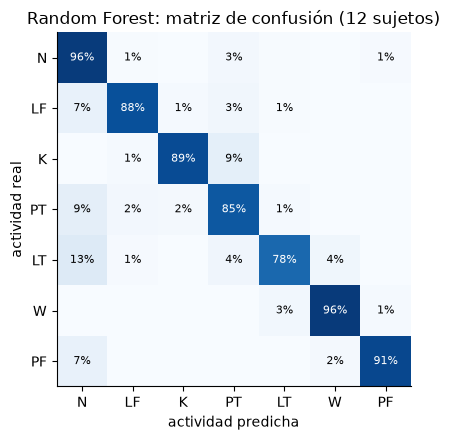

In [10]:
from sklearn.ensemble import RandomForestClassifier

RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)


def run_random_forest(params=RF_PARAMS, folder="RF"):
    rounds = {}
    for held_out in CV_SUBJECTS:
        path = RUN_DIR / folder / f"ronda_s{held_out:02d}.json"
        if path.exists():
            r = json.loads(path.read_text())
        else:
            path.parent.mkdir(parents=True, exist_ok=True)
            t0 = time.time()
            _, train_subjects = split_subjects(held_out)
            train, held = sup_cv["subject"].isin(train_subjects), sup_cv["subject"] == held_out
            clf = RandomForestClassifier(**params).fit(X_tab[train], sup_cv.loc[train, "target"])
            r = {"held_out": held_out, "index": sup_cv.index[held].tolist(), "y": sup_cv.loc[held, "target"].tolist(),
                 "pred": clf.predict(X_tab[held]).tolist(), "minutes": (time.time() - t0) / 60}
            path.write_text(json.dumps(r))
        check_windows(r, held_out, "RF")
        rounds[held_out] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"]), "minutes": r["minutes"]}
    return rounds


report("Random Forest", run_random_forest())

# 5. CNN 1D causal

**Qué es.** El encoder convolucional común (sección 3.1) sin red de contexto. Después de las tres convoluciones se toman la **media y el máximo** de cada uno de los 128 filtros a lo largo de los 48 pasos. Cada filtro ve sólo 7 pasos (0.6 s): capta patrones locales del movimiento, pero no el orden en que aparecen dentro de la ventana.

**Para qué sirve en la comparación.** Si las redes recurrentes la superan, el beneficio viene de modelar la secuencia y no sólo del encoder. Se entrena desde cero con LP-FT.

F1 macro                   F1 por actividad         \
                     media ± desv.       peor sujeto                N     LF   
CNN 1D (desde cero)  0.801 ± 0.039  0.753 (sujeto 2)            0.805  0.865   

                                                        
                         K     PT     LT      W     PF  
CNN 1D (desde cero)  0.846  0.678  0.628  0.924  0.879

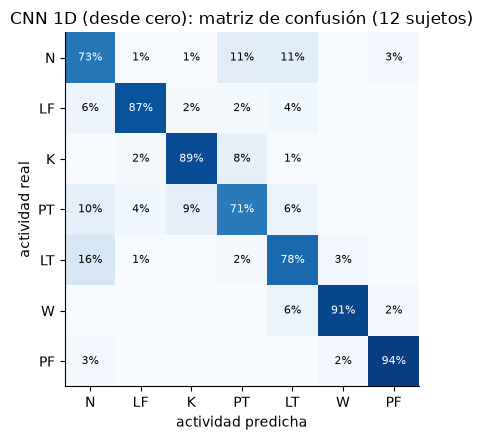

In [11]:
report("CNN 1D", run_network("CNN")["desde cero"], variant="desde cero")

# 6. GRU

**Qué es.** Una red recurrente con dos compuertas: **actualización**, que decide cuánto del estado anterior se conserva, y **reinicio**, que decide cuánto del pasado se usa para calcular el nuevo candidato. Recorre la secuencia `z_t` del encoder paso a paso y resume el pasado en un estado oculto de 256 unidades, con 2 capas. Es la red de contexto del artículo de CPC para reconocimiento de actividades (Haresamudram et al., 2020).

**Variantes.** Desde cero y con preentrenamiento CPC, ambas con LP-FT. Se reporta la de mayor F1.

Variante desde cero: F1 macro 0.866 ± 0.026. Se reporta la variante con CPC (0.878).


F1 macro                   F1 por actividad               \
               media ± desv.       peor sujeto                N    LF      K   
GRU (con CPC)  0.878 ± 0.020  0.835 (sujeto 2)            0.925  0.87  0.902   

                                           
                  PT     LT      W     PF  
GRU (con CPC)  0.827  0.813  0.937  0.902

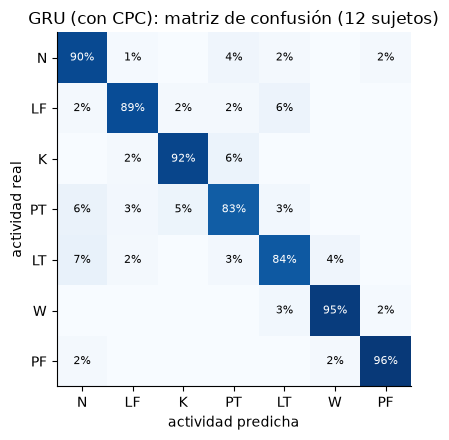

In [12]:
class RecurrentContext(nn.Module):
    """GRU o LSTM de PyTorch: 2 capas de 256 unidades, dropout 0.2 entre capas. z: (B, T, 128) -> c: (B, T, 256), causal."""

    def __init__(self, cell):
        super().__init__()
        self.rnn = {"GRU": nn.GRU, "LSTM": nn.LSTM}[cell](Z_DIM, C_DIM, num_layers=2, dropout=0.2, batch_first=True)

    def forward(self, z):
        return self.rnn(z)[0]


AR_BUILDERS["GRU"] = lambda: RecurrentContext("GRU")
report_best_variant("GRU", {
    "con CPC": load_saved_rounds("GRU/h1s_lpft", "ajuste fino preentrenado", stages=("cpc", "ajuste fino preentrenado")),
    "desde cero": load_saved_rounds("GRU/h1s_lpft", "ajuste fino desde cero", stages=("ajuste fino desde cero",))})

# 7. LSTM

**Qué es.** Como la GRU, pero con tres compuertas (**entrada**, **olvido** y **salida**) y un **estado de celda** separado del estado oculto. El estado de celda sólo se modifica por suma, así que puede conservar información durante más pasos. Usa 2 capas de 256 unidades.

**Variantes.** Desde cero y con preentrenamiento CPC, ambas con LP-FT. Se reporta la de mayor F1.

Variante con CPC: F1 macro 0.747 ± 0.068. Se reporta la variante desde cero (0.854).


F1 macro                   F1 por actividad         \
                   media ± desv.       peor sujeto                N     LF   
LSTM (desde cero)  0.854 ± 0.032  0.787 (sujeto 2)            0.927  0.864   

                                                      
                       K     PT     LT      W     PF  
LSTM (desde cero)  0.834  0.791  0.776  0.925  0.885

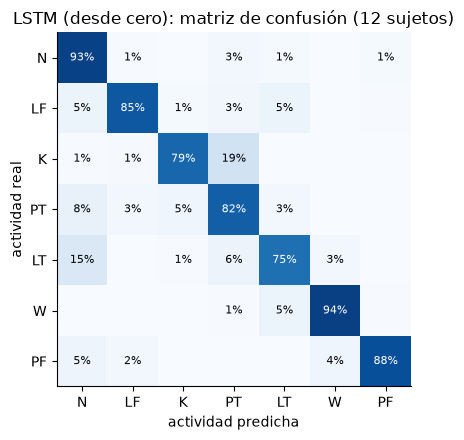

In [13]:
AR_BUILDERS["LSTM"] = lambda: RecurrentContext("LSTM")
report_best_variant("LSTM", {
    "con CPC": load_saved_rounds("LSTM/h1s_lpft", "ajuste fino preentrenado", stages=("cpc", "ajuste fino preentrenado")),
    "desde cero": load_saved_rounds("LSTM/h1s_lpft", "ajuste fino desde cero", stages=("ajuste fino desde cero",))})

# 8. sLSTM (xLSTM con memoria escalar)

**Qué es.** La variante escalar de xLSTM (Beck et al., 2024). Respecto a la LSTM tiene tres cambios:

- una compuerta de entrada **exponencial**, que permite que una entrada nueva reemplace a la memoria con fuerza;
- un **normalizador** que acota el estado oculto, más un **estabilizador** que evita desbordes numéricos;
- **mezcla de memoria por *heads***: la recurrencia sólo combina unidades dentro de cada uno de 4 bloques.

Se apilan 2 bloques residuales, cada uno con normalización y una MLP con compuerta. Es recurrente: procesa la ventana paso a paso.

**Variantes.** Desde cero y con preentrenamiento CPC, con ajuste fino directo (sin la etapa LP; hasta 15 épocas, paciencia 3). Se reporta la de mayor F1.

Variante con CPC: F1 macro 0.871 ± 0.031. Se reporta la variante desde cero (0.875).


F1 macro                   F1 por actividad         \
                    media ± desv.       peor sujeto                N     LF   
sLSTM (desde cero)  0.875 ± 0.028  0.816 (sujeto 2)            0.923  0.878   

                                                       
                        K     PT     LT      W     PF  
sLSTM (desde cero)  0.904  0.816  0.797  0.934  0.899

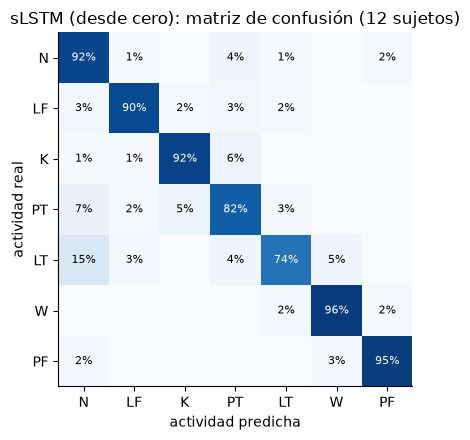

In [14]:
class BlockDiagonalLinear(nn.Module):
    """Capa lineal block-diagonal: cada head sólo mezcla sus propias dimensiones. x: (..., dim) -> (..., dim)."""

    def __init__(self, dim, n_blocks, bias=True):
        super().__init__()
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x):
        shape = x.shape
        y = torch.einsum("...nd,ned->...ne", x.reshape(*shape[:-1], self.n_blocks, self.block), self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias


class sLSTMCell(nn.Module):
    """Celda sLSTM (Beck et al., 2024, Ec. 34–40, estabilizada con Ec. 15–17). x: (B, T, dim) -> h: (B, T, dim)."""

    def __init__(self, dim, n_heads):
        super().__init__()
        self.W = nn.Linear(dim, 4 * dim)                                           # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)          # al inicio, la compuerta de olvido recuerda

    def forward(self, x):
        B, T, D = x.shape
        Wx = self.W(x)
        h = c = n = m = x.new_zeros(B, D)
        out = []
        for t in range(T):
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + torch.cat([r(h) for r in self.R], dim=-1)).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)
            m_new = torch.maximum(log_f + m, i_pre)                                # estabilizador
            i_gate, f_gate = torch.exp(i_pre - m_new), torch.exp(log_f + m - m_new)
            c = f_gate * c + i_gate * torch.tanh(z_pre)                            # estado de celda
            n = f_gate * n + i_gate                                                # normalizador
            h = torch.sigmoid(o_pre) * c / n                                       # estado oculto
            m = m_new
            out.append(h)
        return torch.stack(out, dim=1)


class sLSTMBlock(nn.Module):
    """x -> LayerNorm -> sLSTM -> GroupNorm -> (+x) -> LayerNorm -> MLP con compuerta (×4/3, GeLU) -> (+x)."""

    def __init__(self, dim, n_heads=4, dropout=0.2):
        super().__init__()
        inner = int(round(4 / 3 * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell, self.gn = sLSTMCell(dim, n_heads), nn.GroupNorm(n_heads, dim)
        self.up_a, self.up_b, self.down = nn.Linear(dim, inner), nn.Linear(dim, inner), nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        h = self.cell(self.ln1(x))
        x = x + self.drop(self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape))
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))


class xLSTMContext(nn.Module):
    """Proyección a 256 y 2 bloques xLSTM residuales. z: (B, T, 128) -> c: (B, T, 256), causal."""

    def __init__(self, block, n_blocks=2):
        super().__init__()
        self.proj = nn.Linear(Z_DIM, C_DIM)
        self.blocks = nn.ModuleList([block(C_DIM) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(C_DIM)

    def forward(self, z):
        x = self.proj(z)
        for b in self.blocks:
            x = b(x)
        return self.ln_out(x)


AR_BUILDERS["sLSTM"] = lambda: xLSTMContext(sLSTMBlock)
report_best_variant("sLSTM", {
    "con CPC": load_saved_rounds("sLSTM/h1s", "ajuste fino preentrenado", stages=("cpc", "ajuste fino preentrenado")),
    "desde cero": load_saved_rounds("sLSTM/h1s", "ajuste fino desde cero", stages=("ajuste fino desde cero",))})

# 9. mLSTM (xLSTM con memoria matricial)

**Qué es.** La variante matricial de xLSTM (Beck et al., 2024). Cada *head* guarda una **matriz** de memoria clave → valor, `C_t = f_t C_{t−1} + i_t v_t k_tᵀ`, que se lee con una consulta: `h_t ∝ C_t q_t`. Como no mezcla estados ocultos entre instantes, toda la ventana se calcula **en paralelo** con una matriz causal de 48 × 48, igual que una atención lineal con compuertas.

Se apilan 2 bloques. Cada bloque proyecta al doble de dimensiones y aplica una convolución causal antes de `q` y `k`. Tiene una compuerta de salida externa.

**Variante.** Sólo desde cero, con LP-FT. No se entrenó la variante con CPC: en las demás redes recurrentes las dos variantes empataron (GRU y sLSTM) o el preentrenamiento empeoró el resultado (LSTM), así que es poco probable que cambie la comparación y duplicaría el tiempo de entrenamiento.

F1 macro                   F1 por actividad        \
                    media ± desv.       peor sujeto                N    LF   
mLSTM (desde cero)  0.862 ± 0.041  0.775 (sujeto 2)            0.909  0.87   

                                                      
                        K     PT     LT      W    PF  
mLSTM (desde cero)  0.866  0.794  0.778  0.936  0.89

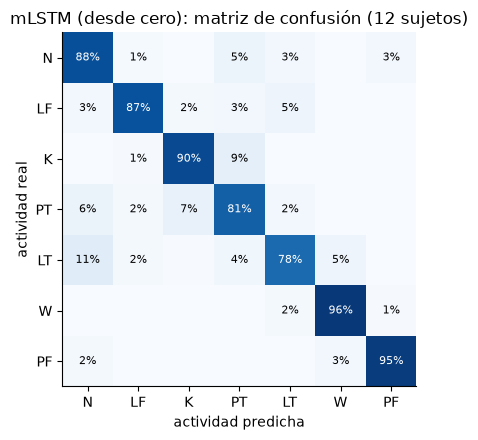

In [15]:
def mlstm_parallel(q, k, v, i_pre, f_pre, n_heads):
    """mLSTM en forma paralela estabilizada (Apéndice A.3, Ec. 79–86). q, k, v: (B, T, D); i_pre, f_pre: (B, T, H) -> (B, T, D).
    Equivale a C_t = f_t C_{t-1} + i_t v_t k_tᵀ, n_t = f_t n_{t-1} + i_t k_t, h_t = C_t q_t / max(|n_tᵀ q_t|, 1); causal."""
    B, T, D = q.shape
    dh = D // n_heads
    q, k, v = [x.view(B, T, n_heads, dh).transpose(1, 2) for x in (q, k, v)]              # (B, H, T, dh)
    i_pre, f_pre = i_pre.transpose(1, 2), f_pre.transpose(1, 2)                           # (B, H, T)
    cum = torch.cumsum(F.logsigmoid(f_pre), dim=-1)
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()
    log_D = (cum.unsqueeze(-1) - cum.unsqueeze(-2) + i_pre.unsqueeze(-2)).masked_fill(~causal, float("-inf"))
    m = log_D.amax(dim=-1, keepdim=True)                                                 # estabilizador por fila
    C = (q @ k.transpose(-2, -1)) / math.sqrt(dh) * torch.exp(log_D - m)
    n = torch.maximum(C.sum(dim=-1, keepdim=True).abs(), torch.exp(-m))                  # normalizador
    return ((C / n) @ v).transpose(1, 2).reshape(B, T, D)


class mLSTMBlock(nn.Module):
    """Bloque mLSTM con pre up-projection (Fig. 11 del artículo):
    x -> LayerNorm -> ×2 en dos ramas: [conv causal + Swish -> q, k; v; compuertas -> mLSTM -> GroupNorm + skip] · Swish(rama 2)
      -> proyección a dim -> (+x)."""

    def __init__(self, dim, n_heads=4, dropout=0.2, conv_kernel=4, qkv_block=4):
        super().__init__()
        inner = 2 * dim
        self.n_heads, self.conv_kernel = n_heads, conv_kernel
        self.ln = nn.LayerNorm(dim)
        self.up_cell, self.up_gate = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.conv = nn.Conv1d(inner, inner, conv_kernel, groups=inner)
        self.q, self.k, self.v = (BlockDiagonalLinear(inner, inner // qkv_block) for _ in range(3))
        self.igate, self.fgate = nn.Linear(3 * inner, n_heads), nn.Linear(3 * inner, n_heads)
        with torch.no_grad():
            self.fgate.bias.copy_(torch.linspace(3.0, 6.0, n_heads))
            nn.init.normal_(self.igate.bias, 0.0, 0.1)
        self.gn = nn.GroupNorm(n_heads, inner)
        self.skip = nn.Parameter(torch.ones(inner))
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        y = self.ln(x)
        x_cell, x_gate = self.up_cell(y), self.up_gate(y)
        x_conv = F.silu(self.conv(F.pad(x_cell.transpose(1, 2), (self.conv_kernel - 1, 0))).transpose(1, 2))
        q, k, v = self.q(x_conv), self.k(x_conv), self.v(x_cell)
        qkv = torch.cat([q, k, v], dim=-1)
        h = mlstm_parallel(q, k, v, self.igate(qkv), self.fgate(qkv), self.n_heads)
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape) + self.skip * x_conv
        return x + self.drop(self.down(h * F.silu(x_gate)))


AR_BUILDERS["mLSTM"] = lambda: xLSTMContext(mLSTMBlock)
report("mLSTM", run_network("mLSTM")["desde cero"], variant="desde cero")

# 10. Comparativos

La tabla ordena los modelos por F1 macro medio en los 12 sujetos e incluye el tiempo de entrenamiento:

- **min por ronda:** promedio de minutos para entrenar una ronda, incluido el preentrenamiento CPC cuando la variante lo usa.
- **h LOSO:** el total de las 12 rondas.

Random Forest, CNN y mLSTM se entrenaron en el equipo de este notebook; GRU, LSTM y sLSTM, en otro equipo, así que su tiempo es orientativo. La regresión logística sobre la media de cada variable aparece como **referencia mínima**.

La figura muestra el F1 macro de cada sujeto (puntos) y la media ± desviación de cada modelo (barra).

,variante,F1 macro,desv.,peor sujeto,min por ronda,h LOSO
modelo,,,,,,
Random Forest,—,0.894,0.026,0.823,0.2,0.03
GRU,con CPC,0.878,0.020,0.835,5.0,1.00
sLSTM,desde cero,0.875,0.028,0.816,10.1,2.01
mLSTM,desde cero,0.862,0.041,0.775,12.6,2.51
LSTM,desde cero,0.854,0.032,0.787,3.9,0.79
CNN 1D,desde cero,0.801,0.039,0.753,0.9,0.18
Referencia: regresión logística (medias),—,0.615,0.043,0.551,—,—


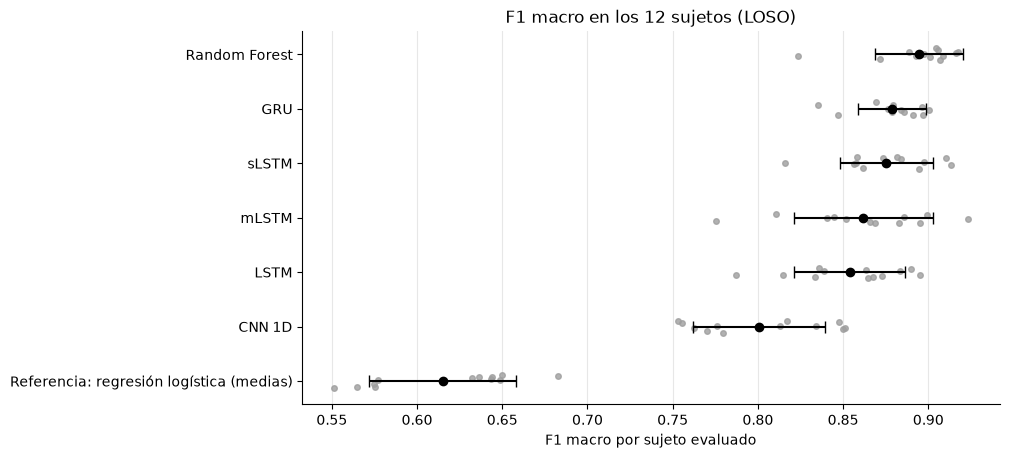

Dos modelos con mayor F1 macro medio: Random Forest y GRU


In [16]:
reference_rounds = load_saved_rounds("manuales", "características manuales (sonda)", name="ronda_s{:02d}.json")
reference = subject_f1(reference_rounds)
REFERENCE = "Referencia: regresión logística (medias)"
summary = pd.DataFrame([{"modelo": m, "variante": r["variante"], "F1 macro": r["f1_sujeto"].mean(), "desv.": r["f1_sujeto"].std(),
                         "peor sujeto": r["f1_sujeto"].min(), "min por ronda": r["minutos_por_ronda"],
                         "h LOSO": r["minutos_por_ronda"] * len(CV_SUBJECTS) / 60} for m, r in RESULTS.items()]
                       ).set_index("modelo").sort_values("F1 macro", ascending=False)
summary.loc[REFERENCE] = {"variante": "—", "F1 macro": reference.mean(), "desv.": reference.std(), "peor sujeto": reference.min(),
                          "min por ronda": np.nan, "h LOSO": np.nan}
display(summary.style.format({"F1 macro": "{:.3f}", "desv.": "{:.3f}", "peor sujeto": "{:.3f}", "min por ronda": "{:.1f}",
                              "h LOSO": "{:.2f}"}, na_rep="—"))

order = list(summary.index[::-1])
fig, ax = plt.subplots(figsize=(9, 0.55 * len(order) + 1))
for i, m in enumerate(order):
    f1 = reference if m == REFERENCE else RESULTS[m]["f1_sujeto"]
    ax.scatter(f1, np.full(len(f1), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(f1)), s=16, color="#9e9e9e", alpha=0.8, zorder=2)
    ax.errorbar(f1.mean(), i, xerr=f1.std(), fmt="o", color="black", capsize=4, zorder=3)
ax.set(yticks=range(len(order)), yticklabels=order, xlabel="F1 macro por sujeto evaluado", title="F1 macro en los 12 sujetos (LOSO)")
ax.grid(axis="x", alpha=0.3)
plt.show()

top2 = list(summary.drop(REFERENCE).index[:2])
print(f"Dos modelos con mayor F1 macro medio: {top2[0]} y {top2[1]}")

**F1 por actividad.** Con las predicciones de los 12 sujetos juntas. En negritas, el modelo con mayor F1 en cada actividad.

In [17]:
ref_y = np.concatenate([r["y"] for _, r in sorted(reference_rounds.items())])
ref_pred = np.concatenate([r["pred"] for _, r in sorted(reference_rounds.items())])
per_activity = pd.DataFrame({m: RESULTS[m]["f1_clase"] for m in summary.index if m != REFERENCE}).T
per_activity.loc[REFERENCE] = f1_score(ref_y, ref_pred, labels=range(len(LABELS)), average=None, zero_division=0)
per_activity.columns = [f"{lab} ({LABEL_NAMES[lab]})" for lab in LABELS]
display(per_activity.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold"))

,N (Postura neutral),LF (Levantar desde el piso),K (Mantener levantado),PT (Colocar en la mesa),LT (Levantar desde la mesa),W (Caminar / cargar),PF (Colocar en el piso)
Random Forest,0.936,0.890,0.917,0.841,0.847,0.946,0.912
GRU,0.925,0.870,0.902,0.827,0.813,0.937,0.902
sLSTM,0.923,0.878,0.904,0.816,0.797,0.934,0.899
mLSTM,0.909,0.870,0.866,0.794,0.778,0.936,0.890
LSTM,0.927,0.864,0.834,0.791,0.776,0.925,0.885
CNN 1D,0.805,0.865,0.846,0.678,0.628,0.924,0.879
Referencia: regresión logística (medias),0.457,0.660,0.654,0.475,0.368,0.882,0.845


### Conclusión

- **El Random Forest es el mejor modelo:** F1 macro de 0.894 ± 0.026. Supera a la GRU en 11 de los 12 sujetos y tiene el mayor F1 en las siete actividades. Las cinco estadísticas por variable (media, desviación, mínimo, máximo y pendiente) describen bien la ventana. La referencia que sólo usa la media queda en 0.615, así que la información útil está en la dispersión, los extremos y la tendencia del movimiento, no sólo en la postura promedio. Además, es el modelo más barato: menos de un minuto por ronda.
- **Las redes recurrentes quedan entre 0.854 y 0.878**, con diferencias pequeñas entre ellas. La GRU y la sLSTM están empatadas (la GRU gana en 5 de 12 sujetos). La GRU varía menos entre personas y tarda la mitad.
- **La recurrencia aporta sobre la convolución:** las cuatro redes recurrentes superan a la CNN (0.801).
- **El preentrenamiento CPC no cambia el resultado de forma consistente:** +0.012 en la GRU, −0.004 en la sLSTM y −0.107 en la LSTM.
- **Las actividades más difíciles son `LT` y `PT`** en todos los modelos; `N` y `W` son las más fáciles. El sujeto 2 es el peor para todos los modelos.

**Para el ajuste se eligen el Random Forest y la GRU con CPC.**

# 11. Ajuste de los dos mejores modelos

**Protocolo.** Se entrena con los sujetos 1–10 y cada configuración se evalúa con los sujetos 11 y 12 (F1 macro medio de los dos). Ninguna configuración se elige con el LOSO. La mejor de cada modelo se vuelve a evaluar en las 12 rondas LOSO para compararla con la versión base.

| Modelo | Hiperparámetros | Valores | Configuraciones |
|---|---|---|---|
| Random Forest | número de árboles · fracción de características por división · hojas mínimas · profundidad máxima | 300, 600 · √150, 30 % · 1, 2, 5 · sin límite, 20 | 24 |
| GRU con CPC | tasa de aprendizaje de la red · dropout de la cabeza · *weight decay* | 3e-5, 1e-4, 3e-4 · 0.2, 0.5 · 1e-4, 1e-2 | 12 |

En la GRU, el preentrenamiento CPC se hace una sola vez y se comparte entre las 12 configuraciones; sólo cambia el ajuste fino. La configuración base está incluida en ambas búsquedas.

**Tiempo estimado:** unos 10 min para el Random Forest y unos 45 min para la GRU. El LOSO de los dos modelos ajustados tarda alrededor de 1 h más. Cada resultado se guarda al terminar, así que una ejecución interrumpida continúa donde se quedó.

In [18]:
TUNE_TRAIN, TUNE_VAL = tuple(range(1, 11)), (11, 12)
TUNE_DIR = RUN_DIR / "ajuste"
TUNE_DIR.mkdir(parents=True, exist_ok=True)


def val_f1(y, pred, subjects):
    """F1 macro medio de los sujetos de validación."""
    return float(np.mean([f1_score(y[subjects == s], pred[subjects == s], average="macro") for s in TUNE_VAL]))


def show_search(rows, base):
    """Las 5 mejores configuraciones y la mejor (como dict); `base` es la configuración usada en el LOSO."""
    best = max(rows, key=lambda r: r["F1 validación"])
    base_f1 = next(r["F1 validación"] for r in rows if all(r[k] == v for k, v in base.items()))
    print(f"Configuración base: F1 {base_f1:.3f} | mejor: {best['F1 validación']:.3f}")
    display(pd.DataFrame(rows).sort_values("F1 validación", ascending=False).head(5).reset_index(drop=True)
            .style.format({"F1 validación": "{:.3f}", "min": "{:.1f}"}, na_rep="sin límite"))
    return {k: best[k] for k in base}


# ----------------------------- 11.1 Random Forest -----------------------------
RF_GRID = [dict(n_estimators=n, max_features=mf, min_samples_leaf=leaf, max_depth=d)
           for n in (300, 600) for mf in ("sqrt", 0.3) for leaf in (1, 2, 5) for d in (None, 20)]
path = TUNE_DIR / "rf.json"
if path.exists():
    rf_rows = json.loads(path.read_text())
else:
    train, val = sup_cv["subject"].isin(TUNE_TRAIN), sup_cv["subject"].isin(TUNE_VAL)
    y_val, s_val = sup_cv.loc[val, "target"].to_numpy(), sup_cv.loc[val, "subject"].to_numpy()
    rf_rows = []
    for g in RF_GRID:
        t0 = time.time()
        clf = RandomForestClassifier(**{**RF_PARAMS, **g}).fit(X_tab[train], sup_cv.loc[train, "target"])
        rf_rows.append({**g, "F1 validación": val_f1(y_val, clf.predict(X_tab[val]), s_val), "min": (time.time() - t0) / 60})
    path.write_text(json.dumps(rf_rows))
print("Random Forest")
RF_BEST = show_search(rf_rows, {k: RF_PARAMS.get(k) for k in RF_GRID[0]})

Random Forest
Configuración base: F1 0.907 | mejor: 0.910


,n_estimators,max_features,min_samples_leaf,max_depth,F1 validación,min
0,300,sqrt,5,sin límite,0.910,0.2
1,600,sqrt,5,sin límite,0.910,0.4
2,600,sqrt,5,20.000000,0.910,0.4
3,300,sqrt,5,20.000000,0.909,0.2
4,600,0.300000,5,sin límite,0.908,1.7


In [19]:
# ----------------------------- 11.2 GRU con CPC -----------------------------
GRU_GRID = [dict(lr_backbone=lr, head_dropout=hd, wd=wd) for lr in (3e-5, 1e-4, 3e-4) for hd in (0.2, 0.5) for wd in (1e-4, 1e-2)]
path = TUNE_DIR / "gru.json"
gru_rows = json.loads(path.read_text()) if path.exists() else []
if len(gru_rows) < len(GRU_GRID):
    sets = make_split(TUNE_TRAIN, TUNE_VAL)
    set_series(apply_scaler(fit_scaler(TUNE_TRAIN)))
    s_val = sup_cv.loc[sets["val"]["index"], "subject"].to_numpy()
    cpc_path = TUNE_DIR / "gru_cpc.pt"            # el CPC se entrena una vez y se comparte entre configuraciones
    if not cpc_path.exists():
        torch.save(train_cpc("GRU", sets, SEED)[0].state_dict(), cpc_path)
    cpc_state = torch.load(cpc_path, map_location=DEVICE)
    for g in GRU_GRID[len(gru_rows):]:
        backbone = build_backbone("GRU", SEED)
        backbone.load_state_dict(cpc_state)
        model, info = finetune(backbone, sets, SEED, **g)
        gru_rows.append({**g, "F1 validación": val_f1(sets["val"]["y"], predict(model, sets["val"]["starts"]), s_val),
                         "época": info["best_epoch"], "min": info["minutes"]})
        path.write_text(json.dumps(gru_rows))
        log(f"ajuste GRU {len(gru_rows)}/{len(GRU_GRID)} | {g} | F1 {gru_rows[-1]['F1 validación']:.3f}")
print("GRU con CPC")
GRU_BEST = show_search(gru_rows, {k: FT[k] for k in GRU_GRID[0]})

GRU con CPC
Configuración base: F1 0.900 | mejor: 0.907


,lr_backbone,head_dropout,wd,F1 validación,época,min
0,0.000300,0.500000,0.010000,0.907,14,3.6
1,0.000300,0.500000,0.000100,0.906,14,3.7
2,0.000100,0.200000,0.000100,0.900,20,5.0
3,0.000100,0.200000,0.010000,0.898,20,4.9
4,0.000300,0.200000,0.000100,0.898,6,2.4


In [20]:
# ----------------------------- 11.3 LOSO de los modelos ajustados -----------------------------
tuned = {"Random Forest": run_random_forest({**RF_PARAMS, **RF_BEST}, folder="RF_ajustado"),
         "GRU": run_network("GRU", ("con CPC",), ft=GRU_BEST, folder="GRU_ajustada")["con CPC"]}
rows = []
for model, rounds in tuned.items():
    base, f1 = RESULTS[model]["f1_sujeto"], subject_f1(rounds)
    rows.append({"modelo": model, "F1 base": base.mean(), "F1 ajustado": f1.mean(), "desv.": f1.std(), "peor sujeto": f1.min(),
                 "sujetos que mejoran": f"{(f1 > base).sum()} de {len(f1)}", "min por ronda": np.mean([r["minutes"] for r in rounds.values()])})
display(pd.DataFrame(rows).set_index("modelo").style.format(
    {"F1 base": "{:.3f}", "F1 ajustado": "{:.3f}", "desv.": "{:.3f}", "peor sujeto": "{:.3f}", "min por ronda": "{:.1f}"}))

,F1 base,F1 ajustado,desv.,peor sujeto,sujetos que mejoran,min por ronda
modelo,,,,,,
Random Forest,0.894,0.893,0.027,0.818,7 de 12,0.2
GRU,0.878,0.879,0.035,0.808,9 de 12,4.5


# 12. Conclusiones globales

**Modelo final: Random Forest.**

- **Es el modelo con mejor desempeño.** Obtiene un F1 macro de 0.894 ± 0.026 en los 12 sujetos, con el mayor F1 en las siete actividades.
- **El ajuste no cambió el resultado.** El Random Forest ajustado obtuvo 0.893 y la GRU ajustada, 0.879, y el Random Forest siguió superando a la GRU en 10 de los 12 sujetos. Por eso se conserva el Random Forest con su configuración original.
- **Es también el más barato:** se entrena en segundos y predice en milisegundos en CPU.

Por el momento se considera el modelo final. Antes de la evaluación con los sujetos de prueba (13 y 14) se harán experimentos adicionales para ver si las redes neuronales pueden superarlo:

**Ajustar la arquitectura y el preentrenamiento de las redes.** En este avance sólo se ajustó el entrenamiento de la cabeza y la tasa de aprendizaje; la arquitectura y el preentrenamiento CPC venían de experimentos con sEMG. Se explorarán el tamaño de la red de contexto, el número de capas y el horizonte de predicción de CPC, con validación por sujeto y varias semillas.

Además se probará el algoritmo **Contrastive Active Inference** (Mazzaglia et al., 2021). Propone un objetivo contrastivo para aprender el modelo interno del mundo de un agente, con menos costo computacional que los métodos basados en verosimilitud. Se evaluará como alternativa autosupervisada al preentrenamiento CPC.

**Referencia:** Mazzaglia, P., Verbelen, T., & Dhoedt, B. (2021). Contrastive active inference. *Advances in Neural Information Processing Systems, 34* (NeurIPS 2021). https://arxiv.org/abs/2110.10083

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Estructurar el notebook y redactar el texto: resumen, tabla de modelos, descripción de cada modelo y protocolo de evaluación  | Celdas de texto 1–3, 5, 9, 11, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 35 y 39 | El equipo definió la estructura, los seis modelos, las métricas y el nivel de detalle; revisó la redacción y pidió ajustes  |
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Escribir el código nuevo de configuración, formato de entrada, figura de ventanas y funciones de evaluación | Celdas 4, 12, 13 y 15 (secciones 1–3) | Se revisaron las formas de entrada impresas y la figura; un control automático comprueba que las ventanas evaluadas coinciden con las de los resultados ya entrenados |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Isaura Yutsil Flores Escamilla | Entrenó y evaluó en validación cruzada LOSO las redes GRU, LSTM y sLSTM, con y sin preentrenamiento CPC, y la referencia de regresión logística sobre características manuales. |
| Paola Alejandra León Guarneros | Entrenó el Random Forest, la CNN 1D y la mLSTM, integró la comparación de los seis modelos y realizó el ajuste de hiperparámetros de los dos mejores. |
| Dylan Ulises Quiroz Hernández | Realizó el análisis exploratorio de los nuevos datos de captura de movimiento (MVNX), base para la selección de variables de entrada. |

### Decisiones principales

<small><b>Decisión 1:</b> Comparar cada red recurrente con su variante de entrenamiento de mejor desempeño</small>

- <small>Justificación: En experimentos previos, cada red se entrenó con varias metodologías (preentrenamiento CPC con ajuste fino, entrenamiento desde cero y clasificadores lineales sobre la representación congelada). Para comparar modelos y no protocolos de entrenamiento, se conservó la variante con mayor F1 de cada red. Por la misma razón, la mLSTM se entrenó sólo desde cero: en las demás redes, el preentrenamiento no cambió el resultado de forma consistente y duplicaba el tiempo de entrenamiento.</small>
- <small>Alternativa descartada y motivo: Presentar todas las variantes de cada red, porque multiplicaba las comparaciones sin cambiar la elección del modelo, y los clasificadores sobre la representación congelada son controles experimentales, no candidatos a modelo final.</small>

<small><b>Decisión 2:</b> Incluir un modelo clásico de aprendizaje automático (Random Forest)</small>

- <small>Justificación: Hasta este avance sólo se habían trabajado redes neuronales, porque el enfoque se basó directamente en el artículo de CPC para reconocimiento de actividades humanas (Haresamudram et al., 2020). Un modelo clásico sobre estadísticas de cada ventana amplía la variedad de algoritmos y mide si la complejidad de las redes se justifica. Resultó el modelo con mejor desempeño.</small>
- <small>Alternativa descartada y motivo: Comparar únicamente arquitecturas de redes neuronales, porque no permitía saber cuánto del desempeño se logra sin aprendizaje profundo.</small>

<small><b>Decisión 3:</b> Usar sólo la captura de movimiento (MVNX) y excluir la sEMG</small>

- <small>Justificación: En un experimento anterior, agregar la sEMG a la captura de movimiento no aportó una mejora apreciable en la clasificación; la información que separa las actividades está en el movimiento. Usar una sola modalidad simplifica la preparación de los datos, aísla la comparación entre modelos y permitió recuperar tres ensayos que se habían excluido sólo por fallas en la sEMG.</small>
- <small>Alternativa descartada y motivo: Combinar sEMG y MVNX como entrada, porque agregaba complejidad de sincronización y preprocesamiento sin una mejora relevante del desempeño.</small>